In [3]:
import cv2
import os
from google.colab.patches import cv2_imshow
from google. colab import runtime
import numpy as np
import PIL
from PIL import Image
import glob
import pathlib
from matplotlib import pyplot as plt
import tensorflow as tf
from tensorflow import keras
from keras import layers
from keras.models import Sequential
from google.colab import drive
import json
drive.mount("/content/drive", force_remount=True)

Mounted at /content/drive


In [ ]:
folder_path = '/content/drive/My Drive/kilobot_images/ref19/repeat7/'
image_files = [f for f in os.listdir(folder_path) if f.endswith(('.jpg', '.jpeg', '.png', '.bmp', '.tiff'))]

# Filter image files to keep only those starting with 'ref9_repeat'
filtered_image_files = [f for f in image_files if f.startswith('ref29_repeat')]
filtered_image_files = image_files
images = {}
for img_file in filtered_image_files:
    img_path = os.path.join(folder_path, img_file)
    img = cv2.imread(img_path)
    if img is not None:
        images[img_file] = img
    else:
        print(f"Warning: Could not load image {img_file}")

print(f"Loaded {len(images)} images.")

Loaded 2 images.


IMG_7075.png
inv min: 74 max: 255
inv dtype: uint8


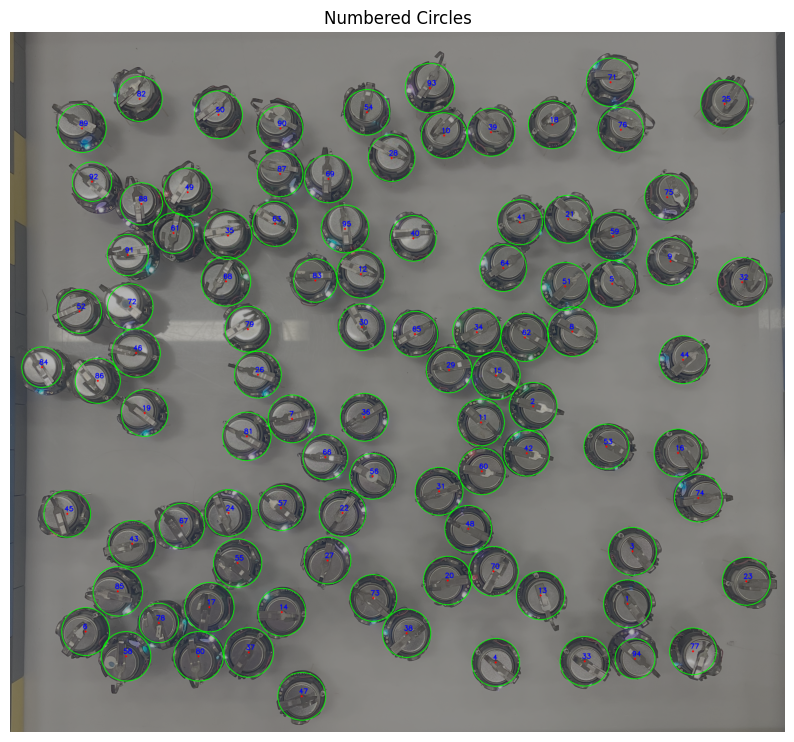

In [ ]:
image_number = 1
image_name = list(images.keys())[image_number] #This gets an image that the user defines
print(image_name)
#Gets the image from drive
im = list(images.items())[image_number][1]
#cv2_imshow(image)

gray = cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)
inv = cv2.bitwise_not(gray)

print("inv min:", inv.min(), "max:", inv.max())
print("inv dtype:", inv.dtype)

if inv.dtype != np.uint8:
    inv = (inv * 255).astype(np.uint8)  # Normalize if needed

# plt.imshow(inv, cmap='gray')
# plt.title("Grayscale Image")
# plt.axis('off')
# plt.show()

# Optional: apply a binary threshold to isolate dark regions
_, thresh = cv2.threshold(inv, 180, 255, cv2.THRESH_BINARY)
blurred = cv2.medianBlur(thresh, 5)

# plt.imshow(thresh, cmap='gray', vmin=0, vmax=255)
# plt.title("Thresholded Image")
# plt.axis('off')
# plt.show()

circles = cv2.HoughCircles(
    blurred,
    cv2.HOUGH_GRADIENT,
    dp=1.5,               # Inverse resolution ratio
    minDist=130,           # Minimum distance between detected centers
    param1=22,            # Upper threshold for internal edge detection - lower = less fussy 22
    param2=27,            # Accumulator threshold for center detection - lower = less fussy. 27
    minRadius=70,          # Minimum radius to detect - was 80
    maxRadius=90,         # Maximum radius to detect - was 100
)

image_with_numbers = im.copy()
circle_centers = []

if circles is not None:
    circles = np.round(circles[0, :]).astype("int")
    for idx, (x, y, r) in enumerate(circles, start=1):
        circle_centers.append({"idx": idx, "x": x, "y": y, "r": r})
        # Draw the circle outline
        cv2.circle(image_with_numbers, (x, y), r, (0, 255, 0), 2)

        # Draw the center of the circle
        cv2.circle(image_with_numbers, (x, y), 2, (0, 0, 255), 3)

        # Put the number near the circle (offset so it's readable)
        cv2.putText(
            image_with_numbers,
            str(idx),
            (x - 10, y - 10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (255, 0, 0),
            2,
        )

# Show the result
plt.figure(figsize=(10, 10))
plt.imshow(cv2.cvtColor(image_with_numbers, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Numbered Circles")
plt.show()

In [ ]:
circle_data = []

if circle_centers is not None:
    for circle in circle_centers:
        idx = circle["idx"]
        x = circle["x"]
        y = circle["y"]
        r = circle["r"]

        # Create mask for the circle
        mask = np.zeros(im.shape[:2], dtype=np.uint8)
        cv2.circle(mask, (x, y), r, 255, thickness=-1)

        # Extract pixels inside circle
        circle_pixels = cv2.bitwise_and(im, im, mask=mask)

        # Sum color channels (BGR)
        blue_sum = np.sum(circle_pixels[:, :, 0])
        red_sum = np.sum(circle_pixels[:, :, 2])

        red_sum *= 0.98
        # Determine dominant color
        if red_sum > blue_sum:
            dominant_color = "red"
        elif blue_sum > red_sum:
            dominant_color = "blue"
        else:
            dominant_color = "unknown"

        circle_data.append({
            "idx": idx,
            "x": x,
            "y": y,
            "radius": r,
            "dominant_color": dominant_color
        })

print(circle_data)


[{'idx': 1, 'x': np.int64(2225), 'y': np.int64(2062), 'radius': np.int64(86), 'dominant_color': 'blue'}, {'idx': 2, 'x': np.int64(1885), 'y': np.int64(1351), 'radius': np.int64(86), 'dominant_color': 'blue'}, {'idx': 3, 'x': np.int64(2243), 'y': np.int64(1873), 'radius': np.int64(86), 'dominant_color': 'red'}, {'idx': 4, 'x': np.int64(1750), 'y': np.int64(2273), 'radius': np.int64(86), 'dominant_color': 'red'}, {'idx': 5, 'x': np.int64(2170), 'y': np.int64(910), 'radius': np.int64(84), 'dominant_color': 'blue'}, {'idx': 6, 'x': np.int64(272), 'y': np.int64(2162), 'radius': np.int64(86), 'dominant_color': 'blue'}, {'idx': 7, 'x': np.int64(1016), 'y': np.int64(1396), 'radius': np.int64(86), 'dominant_color': 'blue'}, {'idx': 8, 'x': np.int64(2026), 'y': np.int64(1082), 'radius': np.int64(89), 'dominant_color': 'blue'}, {'idx': 9, 'x': np.int64(2380), 'y': np.int64(829), 'radius': np.int64(86), 'dominant_color': 'blue'}, {'idx': 10, 'x': np.int64(1564), 'y': np.int64(376), 'radius': np.in

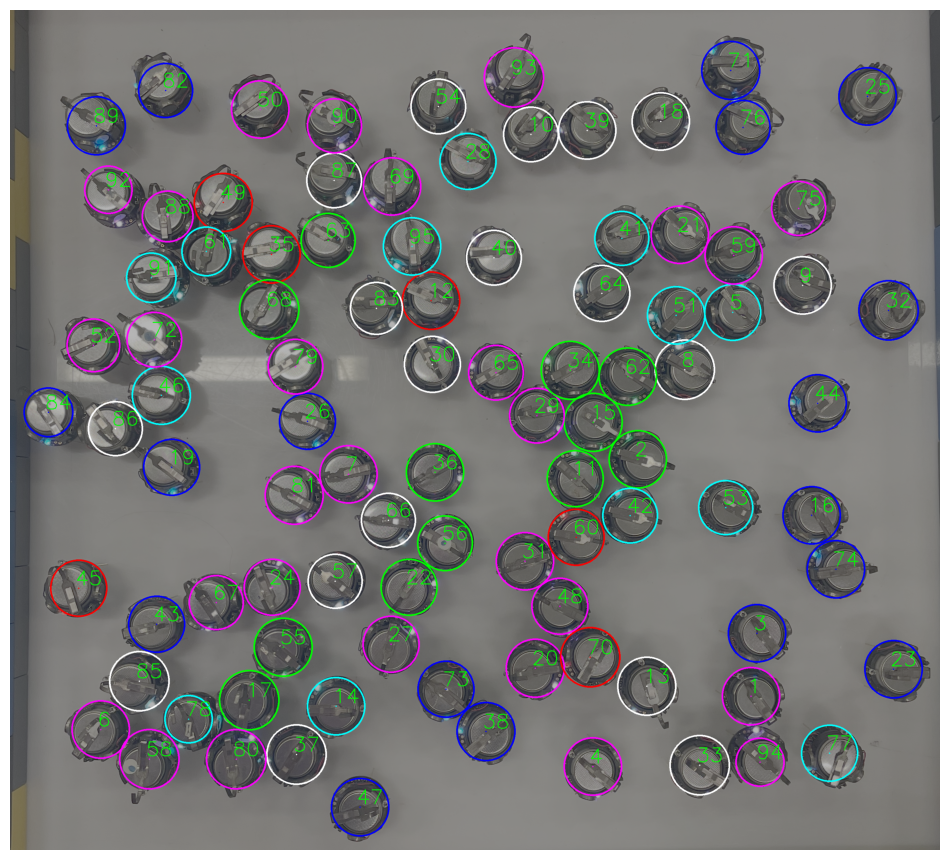

In [ ]:
image_with_colors = im.copy()

# Define BGR colors
color_map = {
    "red": (0, 0, 255),       # Red → (Blue=0, Red=0, Green=255)
    "blue": (255, 0, 0),      # Blue → (Blue=255, Red=0, Green=0)
    "magenta": (255, 0, 255), # Magenta → Blue + Red
    "cyan": (255, 255, 0),    # Cyan → Blue + Green
    "white": (255, 255, 255),
    "green": (0, 255, 0),     # Green in BRG is same as RGB
    "unknown": (0, 0, 0),     # Black
}

for circle in circle_data:
    x, y = circle["x"], circle["y"]
    r = circle["radius"]
    idx = circle["idx"]
    color = color_map.get(circle["dominant_color"], (0, 255, 0))

    # Draw the circle outline in the dominant color
    cv2.circle(image_with_colors, (x, y), r, color, 3)

    # Draw the circle center
    cv2.circle(image_with_colors, (x, y), 2, color, -1)

    # Put the index number near the circle
    cv2.putText(
        image_with_colors,
        str(idx),
        (x - 10, y - 10),
        cv2.FONT_HERSHEY_SIMPLEX,
        2,
        (0, 255, 0),
        2,
    )

plt.figure(figsize=(12, 12))
plt.imshow(cv2.cvtColor(image_with_colors, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

In [ ]:
target_idx = 23
colour = "blue" # red , blue
for circle in circle_data:
    if circle.get("idx") == target_idx:
        circle["dominant_color"] = colour
        break

In [ ]:
idx_to_remove = 101
circle_data = [circle for circle in circle_data if circle.get("idx") != idx_to_remove]


In [ ]:
file_path = '/content/drive/MyDrive/kilobot_images/ref21_circle.json'
with open(file_path, 'r') as f:
    loaded = json.load(f)


In [84]:
array_name = "repeat1"  # or any other key in loaded
circle_data = np.array(loaded[array_name])

In [119]:
# imported circle data

file_path = '/content/drive/MyDrive/kilobot_images/ref20_circle.json'

with open(file_path, 'r') as f:
    loaded = json.load(f)

circle_data = loaded['repeat6']

In [120]:
avg_radius = np.mean([circle["radius"] for circle in circle_data])
print("Average radius:", avg_radius)

Average radius: 98.64646464646465


In [ ]:
230/91.98

2.5005435964340075

Number of robots placed: 110
(10, 11, 3)


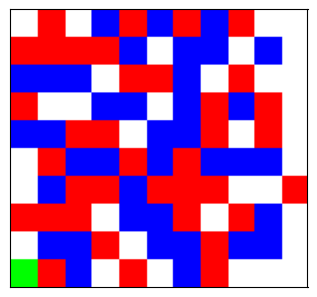

In [121]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from collections import defaultdict

# Sample circle_data assumed provided
coords = np.array([[c['x'], c['y']] for c in circle_data])
colors = [c['dominant_color'] for c in circle_data]

# Normalize coords to (0,0)
coords -= coords.min(axis=0)

circle_spacing = 242/91.98 * avg_radius
grid_coords = (coords / circle_spacing).astype(int)

grid_w = grid_coords[:, 0].max() + 5
grid_h = grid_coords[:, 1].max() + 5

# Compute grid cell centers in original coordinate space
grid_cell_centers = (grid_coords + 0.5) * circle_spacing  # center of each cell

# Group robots by their assigned cell
cell_to_robots = defaultdict(list)
for idx, cell in enumerate(grid_coords):
    cell_to_robots[tuple(cell)].append(idx)

occupied = set()

def find_nearest_free_around_centroid(centroid):
    # Convert centroid to float grid coordinates
    float_x, float_y = centroid / circle_spacing

    # Define search range around centroid grid position
    x_start = int(np.floor(float_x)) - 1
    x_end = int(np.ceil(float_x)) + 1
    y_start = int(np.floor(float_y)) - 1
    y_end = int(np.ceil(float_y)) + 1

    candidates = []
    for nx in range(x_start, x_end + 1):
        for ny in range(y_start, y_end + 1):
            if 0 <= nx < grid_w and 0 <= ny < grid_h and (nx, ny) not in occupied:
                candidate_center = (np.array([nx, ny]) + 0.5) * circle_spacing
                dist = np.linalg.norm(centroid - candidate_center)
                candidates.append((dist, (nx, ny)))

    if not candidates:
        return None
    candidates.sort(key=lambda x: x[0])
    return candidates[0][1]

new_positions = [None] * len(circle_data)

for cell, robot_indices in cell_to_robots.items():
    cell_center = (np.array(cell) + 0.5) * circle_spacing
    distances = []
    for r_idx in robot_indices:
        dist = np.linalg.norm(coords[r_idx] - cell_center)
        distances.append((dist, r_idx))
    distances.sort(key=lambda x: x[0])

    # Closest robot gets the original cell
    closest_robot = distances[0][1]
    new_positions[closest_robot] = cell
    occupied.add(cell)

    # Others try to find free adjacent cells near their own grid coords
    # for _, r_idx in distances[1:]:
    #   centroid = coords[r_idx]
    #   free_cell = find_nearest_free_around_centroid(centroid)
    #   if free_cell is not None:
    #       new_positions[r_idx] = free_cell
    #       occupied.add(free_cell)
    #   else:
    #       new_positions[r_idx] = None

# Create grid image
img = np.zeros((grid_h, grid_w, 3), dtype=np.uint8) # black
img = np.full((grid_h, grid_w, 3), fill_value=255, dtype=np.uint8) #white

color_map = {
    "red": (255, 0, 0),
    "blue": (0, 0, 255),
    "unknown": (0, 255, 0),
}

color_map = {
    "red": (255, 0, 0),       # Red
    "blue": (0, 0, 255),      # Blue
    "magenta": (255, 0, 255), # Magenta
    "cyan": (0, 255, 255),    # Cyan
    "white": (255, 255, 255), # White
    "green": (0, 255, 0),     # Green
    "unknown": (0, 0, 0),     # Black
}

for pos, c in zip(new_positions, colors):
    if pos is not None:
        x, y = pos
        img[y, x] = color_map.get(c, (0, 255, 0))

non_blank_rows = np.any(img != 255, axis=(1, 2))
non_blank_cols = np.any(img != 255, axis=(0, 2))
img = img[non_blank_rows][:, non_blank_cols]

print("Number of robots placed:", np.count_nonzero(np.any(img != 0, axis=-1)))

img_big = cv2.resize(img, (grid_w * 10, grid_h * 10), interpolation=cv2.INTER_NEAREST)
print(img.shape)
# plt.figure(figsize=(10, 5))
# plt.subplot(1, 2, 1)
# plt.imshow(cv2.cvtColor(image_with_colors, cv2.COLOR_BGR2RGB))
# plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(img_big)
plt.xticks([])
plt.yticks([])
plt.tight_layout()
plt.show()


In [ ]:

label_array = np.zeros((img.shape[0], img.shape[1]), dtype=int)

# Mapping RGB values to numeric labels
for name, rgb in color_map.items():
    #label_val = {"unknown": 0, "red": 1, "blue": 2, "green": 3}[name]
    label_val = {"unknown": 0, "red": 10, "blue": 4, "green": 8, "yellow": 9, "green": 8, "cyan": 7, "white":6, "magenta": 5, "blue": 4}[name]
    mask = np.all(img == rgb, axis=2)
    label_array[mask] = label_val
print(np.array(label_array))
print(label_array.shape)

[[ 4  4  5  5  0  6  5  6  6  4  4  4]
 [ 5  5 10  6  5  7  6  0  0  0  5  0]
 [ 0  7  7  8  0  7  6  7  5  5  6  0]
 [ 5  5  0  5  6 10  5  6  8  7  0  4]
 [ 4  7  0  4  0  6  5  8  6  0  4  0]
 [ 6  4  0  5  5  8  0  8  8  0  0  0]
 [ 0  0  0  6  6  8  5 10  7  7  4  0]
 [10  4  5  8  5  8  0  5  0  4  4  0]
 [ 0  6  8  7  0  4  5 10  6  5  0  4]
 [ 5  5  5  6  0  0  4  5  6  5  7  0]
 [ 0  0  0  0  4  0  0  0  0  0  0  0]]
(11, 12)


In [ ]:
def print_numpy_array(arr):
    print("[")
    for row in arr:
        print(f"    {row.tolist()},")
    print("]")
print_numpy_array(label_array)

[
    [4, 4, 5, 5, 0, 6, 5, 6, 6, 4, 4, 4],
    [5, 5, 10, 6, 5, 7, 6, 0, 0, 0, 5, 0],
    [0, 7, 7, 8, 0, 7, 6, 7, 5, 5, 6, 0],
    [5, 5, 0, 5, 6, 10, 5, 6, 8, 7, 0, 4],
    [4, 7, 0, 4, 0, 6, 5, 8, 6, 0, 4, 0],
    [6, 4, 0, 5, 5, 8, 0, 8, 8, 0, 0, 0],
    [0, 0, 0, 6, 6, 8, 5, 10, 7, 7, 4, 0],
    [10, 4, 5, 8, 5, 8, 0, 5, 0, 4, 4, 0],
    [0, 6, 8, 7, 0, 4, 5, 10, 6, 5, 0, 4],
    [5, 5, 5, 6, 0, 0, 4, 5, 6, 5, 7, 0],
    [0, 0, 0, 0, 4, 0, 0, 0, 0, 0, 0, 0],
]


In [ ]:
print(image_name)
print(folder_path)

IMG_7103 (1).png
/content/drive/My Drive/kilobot_images/ref19/repeat10/


In [ ]:
import numpy as np
import os


def delete_array_from_npz(file_path, array_name_to_delete):
    if not os.path.exists(file_path):
        print(f"File not found: {file_path}")
        return

    # Load all existing arrays
    data = dict(np.load(file_path))

    if array_name_to_delete in data:
        print(f"Deleting '{array_name_to_delete}' from {file_path}")
        del data[array_name_to_delete]
        # Re-save without the deleted array
        np.savez(file_path, **data)
    else:
        print(f"'{array_name_to_delete}' not found in {file_path}")

def save_or_append_npz(file_path, array_name, array_data, overwrite=True):
    if os.path.exists(file_path):
        data = dict(np.load(file_path))
        if overwrite and array_name in data:
            delete_array_from_npz(file_path, array_name)
            data = dict(np.load(file_path))  # reload after deletion
    else:
        data = {}

    data[array_name] = array_data
    np.savez(file_path, **data)
    print(f"Saved array '{array_name}' to {file_path}")

file_path = '/content/drive/MyDrive/kilobot_images/ref21.npz'
array_name = 'repeat10'

save_or_append_npz(file_path, array_name, label_array, overwrite=True)

# Load and print to verify
loaded = np.load(file_path)
print("Arrays in file:", list(loaded.keys()))
print(f"Array '{array_name}':\n", loaded[array_name])

Deleting 'repeat10' from /content/drive/MyDrive/kilobot_images/ref21.npz
Saved array 'repeat10' to /content/drive/MyDrive/kilobot_images/ref21.npz
Arrays in file: ['repeat1', 'repeat2', 'repeat4', 'repeat5', 'repeat6', 'repeat7', 'repeat8', 'repeat9', 'repeat10']
Array 'repeat10':
 [[0 1 2 1 2 1 2 1 1 1 0]
 [2 2 2 1 1 1 2 2 1 0 2]
 [0 1 2 2 2 1 2 2 2 1 1]
 [2 1 1 1 1 2 2 2 0 1 0]
 [0 0 2 0 2 1 1 2 2 2 0]
 [0 0 1 1 1 1 1 2 1 2 1]
 [0 2 2 1 1 2 1 0 2 0 2]
 [2 1 2 2 2 0 2 1 2 2 2]
 [1 2 0 1 1 1 2 1 0 1 1]
 [2 1 0 2 0 2 2 3 0 2 1]
 [0 0 0 0 1 0 0 0 0 0 0]]


In [ ]:
import json
import os
import numpy as np

def convert_numpy(obj):
    if isinstance(obj, np.integer):
        return int(obj)
    elif isinstance(obj, np.floating):
        return float(obj)
    elif isinstance(obj, np.ndarray):
        return obj.tolist()
    elif isinstance(obj, list):
        return [convert_numpy(i) for i in obj]
    elif isinstance(obj, dict):
        return {k: convert_numpy(v) for k, v in obj.items()}
    return obj

def save_or_append_json(file_path, array_name, array_data):
    array_data = convert_numpy(array_data)
    if os.path.exists(file_path):
        with open(file_path, 'r') as f:
            data = json.load(f)
    else:
        data = {}
    data[array_name] = array_data
    with open(file_path, 'w') as f:
        json.dump(data, f, indent=2)

file_path = '/content/drive/MyDrive/kilobot_images/ref19_circle.json'
array_name = 'repeat10'

save_or_append_json(file_path, array_name, circle_data)

with open(file_path, 'r') as f:
    loaded = json.load(f)

for name, arr in loaded.items():
    print(f"{name}: {arr}")


repeat1: [{'idx': 1, 'x': 1129, 'y': 1054, 'radius': 99, 'dominant_color': 'blue'}, {'idx': 2, 'x': 1405, 'y': 1319, 'radius': 97, 'dominant_color': 'blue'}, {'idx': 3, 'x': 1493, 'y': 851, 'radius': 99, 'dominant_color': 'blue'}, {'idx': 4, 'x': 1861, 'y': 1510, 'radius': 96, 'dominant_color': 'blue'}, {'idx': 5, 'x': 604, 'y': 1054, 'radius': 99, 'dominant_color': 'blue'}, {'idx': 6, 'x': 1988, 'y': 328, 'radius': 99, 'dominant_color': 'red'}, {'idx': 7, 'x': 1871, 'y': 1039, 'radius': 96, 'dominant_color': 'red'}, {'idx': 8, 'x': 973, 'y': 1198, 'radius': 99, 'dominant_color': 'blue'}, {'idx': 9, 'x': 1192, 'y': 265, 'radius': 99, 'dominant_color': 'blue'}, {'idx': 10, 'x': 1390, 'y': 295, 'radius': 97, 'dominant_color': 'blue'}, {'idx': 11, 'x': 2146, 'y': 1561, 'radius': 96, 'dominant_color': 'red'}, {'idx': 12, 'x': 1858, 'y': 805, 'radius': 97, 'dominant_color': 'red'}, {'idx': 13, 'x': 2384, 'y': 1358, 'radius': 96, 'dominant_color': 'red'}, {'idx': 14, 'x': 1285, 'y': 829, 'ra

Number of robots placed: 76
(11, 11, 3)


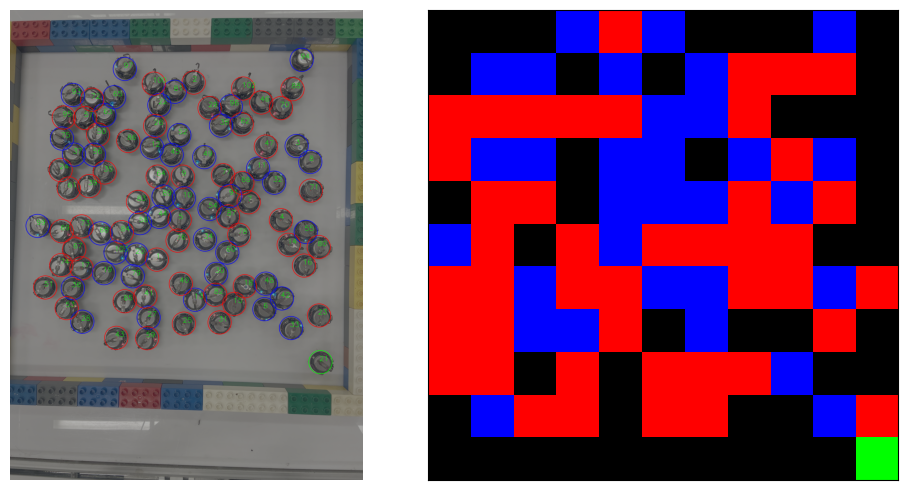

In [ ]:
# import numpy as np
# import cv2
# import matplotlib.pyplot as plt

# # --- Sample input ---
# # Replace with your actual data:
# # circle_data = [{'x': ..., 'y': ..., 'dominant_color': 'red'/'blue'/...}, ...]

# # circle_data = [{'x': ..., 'y': ..., 'dominant_color': 'red'/'blue'/...}, ...]

# coords = np.array([[c['x'], c['y']] for c in circle_data])
# colors = [c['dominant_color'] for c in circle_data]

# # Step 1: Shift so min coordinate is (0,0)
# coords -= coords.min(axis=0)

# # Step 2: Convert real distances to grid locations (1 unit per ~150 px)
# circle_spacing = 240  # threshold for adjacency # average radius * 2.57
# grid_coords = (coords / circle_spacing).astype(int)

# # Step 3: Determine grid size
# grid_w = grid_coords[:, 0].max() + 1
# grid_h = grid_coords[:, 1].max() + 1

# # Step 4: Create blank grid image
# img = np.zeros((grid_h, grid_w, 3), dtype=np.uint8)

# # Step 5: Draw each circle as 1 pixel in the grid
# color_map = {
#     "red": (255, 0, 0),
#     "blue": (0, 0, 255),
#     "unknown": (0, 255, 0),
# }

# for (x, y), c in zip(grid_coords, colors):
#     img[y, x] = color_map.get(c, (0, 255, 0))

# count_nonzero = np.count_nonzero(np.any(img != 0, axis=-1))
# print("Number of robots placed:", count_nonzero)

# # Optional: Upscale for better visualization
# img_big = cv2.resize(img, (grid_w * 10, grid_h * 10), interpolation=cv2.INTER_NEAREST)
# print(img.shape)
# plt.figure(figsize=(10, 5))
# plt.subplot(1, 2, 1)
# plt.imshow(cv2.cvtColor(image_with_colors, cv2.COLOR_BGR2RGB))
# plt.axis("off")

# plt.subplot(1, 2, 2)
# plt.imshow(img_big)
# plt.xticks([])
# plt.yticks([])
# plt.tight_layout()
# plt.show()
